Филатова Римма Б05-325

датасет - Amazon Reviews 2023, McAuley Lab — https://amazon-reviews-2023.github.io/ (https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023)

In [21]:
import os, sys, json, itertools, time, requests
import numpy as np, pandas as pd, scipy.sparse as sp, matplotlib.pyplot as plt
from pathlib import Path
from knn import ItemKNN
from ease import EASE
from als import IALS
from custom_ials import CustomIALS
from fm import FM, build_fm_features
import random
import torch


In [22]:
SEED = 42

In [23]:
def evaluate(model, users, seen, target, k=10, bs=2048):
    n_items = seen.shape[1]
    disc = 1.0 / np.log2(np.arange(2, k + 2))
    cum = np.cumsum(disc)
    nd, rc, hr, shown = ([], [], [], np.zeros(n_items, bool))
    for s in range(0, len(users), bs):
        ub = users[s:s + bs]
        sc = np.asarray(model.score(ub), dtype=np.float32).copy()
        co = seen[ub].tocoo()
        sc[co.row, co.col] = -np.inf
        # Исключаем также объекты, которых не было в обучающем каталоге.
        sc[:, ~eligible_items] = -np.inf
        top = np.argpartition(-sc, k - 1, axis=1)[:, :k]
        top = np.take_along_axis(top, np.argsort(-np.take_along_axis(sc, top, 1), 1), 1)
        tgt = target[ub].toarray() > 0
        hit = np.take_along_axis(tgt, top, 1)
        n = tgt.sum(1)
        nd.append((hit * disc).sum(1) / cum[np.minimum(n, k) - 1])
        rc.append(hit.sum(1) / n)
        hr.append(hit.any(1))
        shown[top.ravel()] = True
    return {f'NDCG@{k}': float(np.concatenate(nd).mean()), f'Recall@{k}': float(np.concatenate(rc).mean()), f'HitRate@{k}': float(np.concatenate(hr).mean()), f'Coverage@{k}': float(shown.mean())}

In [24]:
def to_csr(users, items, n_users, n_items, data=None):
    data = np.ones(len(users), dtype=np.float32) if data is None else np.asarray(data, dtype=np.float32)
    return sp.csr_matrix((data, (users, items)), shape=(n_users, n_items))

In [25]:
def set_seed(s=SEED):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)

In [26]:
set_seed(SEED)
CFG = dict(CATEGORY='Video_Games', MIN_DEG=5, MAX_USERS=12000, MAX_ITEMS=12000, K=10, T_VAL=0.8, T_TEST=0.9, POS_RATING=4, SEED=SEED)
os.makedirs('data', exist_ok=True)
BASE = 'https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023/resolve/main/raw'
URLS = {f"data/{CFG['CATEGORY']}.jsonl": f'{BASE}/review_categories/{CFG['CATEGORY']}.jsonl', f"data/meta_{CFG['CATEGORY']}.jsonl": f'{BASE}/meta_categories/meta_{CFG['CATEGORY']}.jsonl'}

def download(url, path):
    tmp = path + '.part'
    with requests.get(url, stream=True) as r:
        r.raise_for_status()
        with open(tmp, 'wb') as f:
            for ch in r.iter_content(1 << 20):
                f.write(ch)
    os.replace(tmp, path)
for p, u in URLS.items():
    if not os.path.exists(p):
        download(u, p)

## 1. Загрузка данных

In [27]:
rev_path, meta_path = list(URLS)
parts = []
for ch in pd.read_json(rev_path, lines=True, chunksize=500000, dtype=False):
    parts.append(ch[['user_id', 'parent_asin', 'rating', 'timestamp']])
raw = pd.concat(parts, ignore_index=True)
del parts
meta_raw = pd.read_json(meta_path, lines=True, dtype=False)[['parent_asin', 'title', 'main_category', 'store', 'price', 'categories', 'description']]
print('Data size:', len(raw), 'reviews;', raw.user_id.nunique(), 'users;', raw.parent_asin.nunique(), 'obj')
print('Metadata:', meta_raw.shape)
raw.head()

Data size: 4624615 reviews; 2766656 users; 137249 obj
Metadata: (137269, 7)


,user_id,parent_asin,rating,timestamp
0,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,B07DK1H3H5,4.0,2020-12-17 06:33:24.795
1,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,B07SRWRH5D,5.0,2020-04-16 15:31:54.941
2,AGXVBIUFLFGMVLATYXHJYL4A5Q7Q,B07MFMFW34,5.0,2017-03-30 12:37:11.000
3,AFTC6ZR5IKNRDG5JCPVNVMU3XV2Q,B0BCHWZX95,5.0,2019-12-29 16:40:34.017
4,AFTC6ZR5IKNRDG5JCPVNVMU3XV2Q,B00HUWA45W,5.0,2015-03-29 01:18:52.000


## 2. EDA и подготовка
Очистка: удаляем пропуски и дубликаты (оставляем последний отзыв пары), затем итеративный 5-core. Если данных больше лимитов, берём топ-`MAX_ITEMS` объектов по популярности и случайных `MAX_USERS` пользователей (seed=42), снова 5-core.

In [28]:
TOP_ITEMS = 5000
MIN_USER_DEG = 5
MIN_ITEM_DEG = 20
MAX_USERS = 20000
dups = raw.duplicated(['user_id', 'parent_asin']).sum()
df = raw[['user_id', 'parent_asin', 'rating', 'timestamp']].dropna().sort_values('timestamp').drop_duplicates(['user_id', 'parent_asin'], keep='last')

def core_filter(d, min_user, min_item):
    while True:
        n = len(d)
        ic = d['parent_asin'].value_counts()
        d = d[d['parent_asin'].isin(ic[ic >= min_item].index)]
        uc = d['user_id'].value_counts()
        d = d[d['user_id'].isin(uc[uc >= min_user].index)]
        if len(d) == n:
            return d
top_items = df['parent_asin'].value_counts().head(TOP_ITEMS).index
df = df[df['parent_asin'].isin(top_items)]
df = core_filter(df, MIN_USER_DEG, MIN_ITEM_DEG)
if MAX_USERS is not None and df['user_id'].nunique() > MAX_USERS:
    users = df['user_id'].drop_duplicates()
    keep = users.sample(MAX_USERS, random_state=SEED)
    df = df[df['user_id'].isin(keep)]
    df = core_filter(df, MIN_USER_DEG, MIN_ITEM_DEG)
df = df.reset_index(drop=True)
n_users = df['user_id'].nunique()
n_items = df['parent_asin'].nunique()
print('Missing values before cleaning:\n', raw[['user_id', 'parent_asin', 'rating', 'timestamp']].isna().sum())
print('Duplicate user-item pairs:', dups)
print(f"Before cleaning: {len(raw)} interactions, {raw['user_id'].nunique()} users, {raw['parent_asin'].nunique()} items")
print(f'After cleaning: {len(df)} interactions, {n_users} users, {n_items} items')
print(f'Sparsity: {1 - len(df) / (n_users * n_items):.4%}')

Missing values before cleaning:
 user_id        0
parent_asin    0
rating         0
timestamp      0
dtype: int64
Duplicate user-item pairs: 69115
Before cleaning: 4624615 interactions, 2766656 users, 137249 items
After cleaning: 111735 interactions, 13852 users, 1887 items
Sparsity: 99.5725%


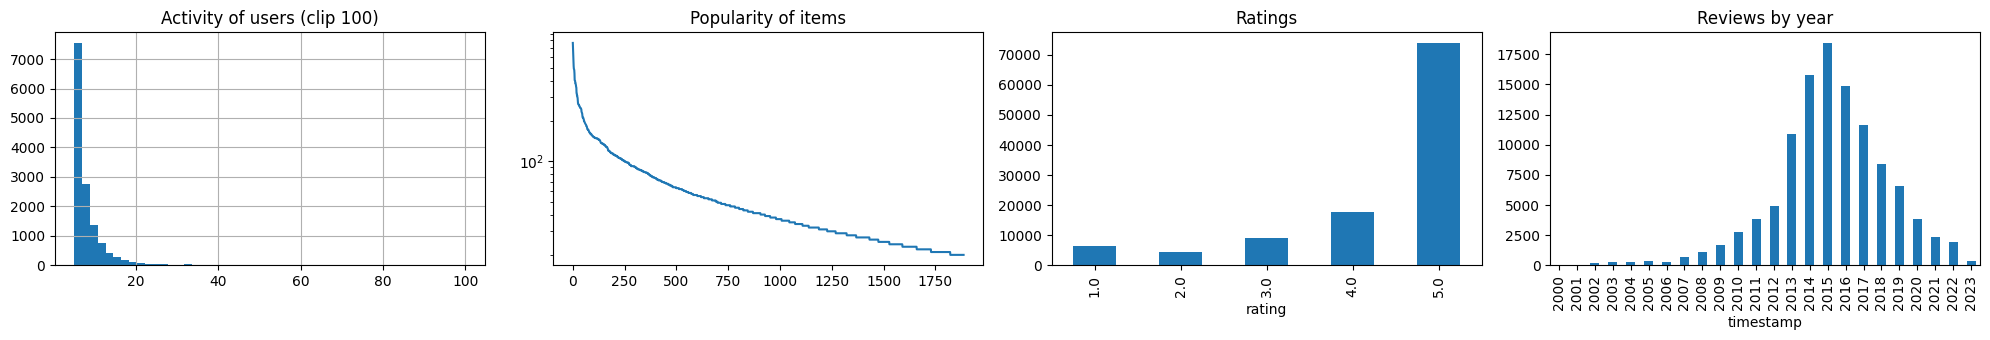

Missing metadata fraction:
 title            0.000000
main_category    0.014308
store            0.000530
price            0.206677
categories       0.000000
dtype: float64
main_category
Video Games                  1659
Computers                     130
All Electronics                44
Cell Phones & Accessories      13
Software                        4
Toys & Games                    2
Sports & Outdoors               2
Tools & Home Improvement        1
Name: count, dtype: int64


In [29]:
df['uid'] = pd.factorize(df.user_id)[0]
items_codes, items_uniq = pd.factorize(df.parent_asin)
df['iid'] = items_codes
meta = meta_raw.drop_duplicates('parent_asin').set_index('parent_asin').reindex(items_uniq).reset_index()
fig, ax = plt.subplots(1, 4, figsize=(20, 3.5))
df.groupby('uid').size().clip(upper=100).hist(bins=50, ax=ax[0])
ax[0].set_title('Activity of users (clip 100)')
df.groupby('iid').size().sort_values(ascending=False).reset_index(drop=True).plot(ax=ax[1], logy=True)
ax[1].set_title('Popularity of items')
df.rating.value_counts().sort_index().plot.bar(ax=ax[2])
ax[2].set_title('Ratings')
pd.to_datetime(df.timestamp, unit='ms').dt.year.value_counts().sort_index().plot.bar(ax=ax[3])
ax[3].set_title('Reviews by year')
plt.tight_layout()
plt.show()
print('Missing metadata fraction:\n', meta[['title', 'main_category', 'store', 'price', 'categories']].isna().mean())
print(meta.main_category.value_counts().head(8))

In [30]:
t_val, t_test = df.timestamp.quantile([CFG['T_VAL'], CFG['T_TEST']])
tr, va, te = (df[df.timestamp < t_val], df[(df.timestamp >= t_val) & (df.timestamp < t_test)], df[df.timestamp >= t_test])
print(len(tr), len(va), len(te))
POS = CFG['POS_RATING']
NU, NI = (n_users, n_items)

def mat(d, pos=False):
    d = d[d.rating >= POS] if pos else d
    return to_csr(d.uid.values, d.iid.values, NU, NI)
train_items = np.unique(tr.iid)
eligible_items = np.zeros(NI, dtype=bool)
eligible_items[train_items] = True

def mask_items(M, items):
    keep = np.zeros(NI, np.float32)
    keep[items] = 1
    return (M @ sp.diags(keep)).tocsr()
X_tr_pos, X_tr_all = (mat(tr, True), mat(tr))
X_trva_pos, X_trva_all = (mat(pd.concat([tr, va]), True), mat(pd.concat([tr, va])))
Y_val = mask_items(mat(va, True), train_items)
Y_test = mask_items(mat(te, True), train_items)
users_val = np.where((np.diff(Y_val.indptr) > 0) & (np.diff(X_tr_all.indptr) > 0))[0]
users_test = np.where((np.diff(Y_test.indptr) > 0) & (np.diff(X_trva_all.indptr) > 0))[0]
print('Validation/test users:', len(users_val), len(users_test))

89388 11173 11174
Validation/test users: 2178 1586


### Протокол ранжирования и релевантность

Рекомендуем объекты каталога Amazon Video Games пользователям с историей отзывов. Релевантным считается **новый объект с оценкой не ниже 4**, появившийся в соответствующем временном окне. Основная метрика выбирается **до** подбора параметров — NDCG@10, дополнительная — Recall@10; также показываем HitRate@10 и Coverage@10. Разбиение глобальное по времени: первые 80% взаимодействий — train, следующие 10% — validation, последние 10% — test. На validation исключаются все объекты, уже известные пользователю по train; на test — по train+validation. Для обоих этапов допустимы только объекты из train-каталога; пользователи без истории и без релевантных объектов в данном окне не участвуют в расчёте. Это **warm-start** протокол, не измеряющий качество для новых пользователей и новых товаров. Все модели оцениваются по одному и тому же бинарному критерию, независимо от своих обучающих сигналов.

**Важная оговорка:** каталог, пользовательская подвыборка и кодировки формируются по всему датасету до временного разбиения. Это создаёт риск смещения отбора в сторону будущей активности, хотя значения целевого тестового взаимодействия не передаются моделям. Для строгой оценки в реальном времени отбор каталога и пользователей нужно выполнять только по прошлому периоду и фиксировать до validation/test. Метаданные также должны быть проверены на доступность на дату рекомендации: текущий снимок карточки товара не гарантирует историческую доступность каждого признака.

## 4. Модели и подбор гиперпараметров (validation, критерий — NDCG@10)

In [31]:
results_val, best = ({}, {})

def tune(name, grid, make_and_fit):
    rows, keys = ([], list(grid))
    for vals in itertools.product(*grid.values()):
        hp = dict(zip(keys, vals))
        t0 = time.time()
        set_seed(SEED)
        m = make_and_fit(hp, 'val')
        met = evaluate(m, users_val, X_tr_all, Y_val)
        rows.append({**hp, **met, 'sec': time.time() - t0})
        print(name, hp, round(met['NDCG@10'], 4))
    r = pd.DataFrame(rows).sort_values('NDCG@10', ascending=False)
    results_val[name] = r
    best[name] = {k: r.iloc[0][k].item() if isinstance(r.iloc[0][k], np.generic) else r.iloc[0][k] for k in keys}
    return r.head(5)

def data_for(stage):
    return (X_tr_pos, tr) if stage == 'val' else (X_trva_pos, pd.concat([tr, va]))

### 4.1 Item-based kNN
Сходство: $$ s_{ij}=\frac{|U_i\cap U_j|}{|U_i|^{\alpha}|U_j|^{1-\alpha}+\lambda} $$
top-k соседей на объект; $$ \hat r_{ui}=\sum_{j\in I_u}s_{ij}$$

In [32]:
tune('ItemKNN', dict(k=[20, 50, 100, 200], shrink=[0, 10, 50], alpha=[0.3, 0.5, 0.7]), lambda hp, st: ItemKNN(**hp).fit(data_for(st)[0]))

ItemKNN {'k': 20, 'shrink': 0, 'alpha': 0.3} 0.0287
ItemKNN {'k': 20, 'shrink': 0, 'alpha': 0.5} 0.0258
ItemKNN {'k': 20, 'shrink': 0, 'alpha': 0.7} 0.0216
ItemKNN {'k': 20, 'shrink': 10, 'alpha': 0.3} 0.0293
ItemKNN {'k': 20, 'shrink': 10, 'alpha': 0.5} 0.0266
ItemKNN {'k': 20, 'shrink': 10, 'alpha': 0.7} 0.0243
ItemKNN {'k': 20, 'shrink': 50, 'alpha': 0.3} 0.03
ItemKNN {'k': 20, 'shrink': 50, 'alpha': 0.5} 0.0284
ItemKNN {'k': 20, 'shrink': 50, 'alpha': 0.7} 0.027
ItemKNN {'k': 50, 'shrink': 0, 'alpha': 0.3} 0.0309
ItemKNN {'k': 50, 'shrink': 0, 'alpha': 0.5} 0.0278
ItemKNN {'k': 50, 'shrink': 0, 'alpha': 0.7} 0.0237
ItemKNN {'k': 50, 'shrink': 10, 'alpha': 0.3} 0.0308
ItemKNN {'k': 50, 'shrink': 10, 'alpha': 0.5} 0.029
ItemKNN {'k': 50, 'shrink': 10, 'alpha': 0.7} 0.0251
ItemKNN {'k': 50, 'shrink': 50, 'alpha': 0.3} 0.0325
ItemKNN {'k': 50, 'shrink': 50, 'alpha': 0.5} 0.0312
ItemKNN {'k': 50, 'shrink': 50, 'alpha': 0.7} 0.029
ItemKNN {'k': 100, 'shrink': 0, 'alpha': 0.3} 0.0322
Item

,k,shrink,alpha,NDCG@10,Recall@10,HitRate@10,Coverage@10,sec
33,200,50,0.3,0.033995,0.056632,0.096419,0.695284,0.075635
24,100,50,0.3,0.033795,0.055598,0.094582,0.721251,0.069127
30,200,10,0.3,0.032782,0.054675,0.093664,0.755697,0.077030
21,100,10,0.3,0.032588,0.054120,0.094123,0.776365,0.067877
15,50,50,0.3,0.032493,0.050943,0.089991,0.754107,0.063222


iALS
$$\min\sum_{u,i}c_{ui}(p_{ui}-x_u^\top y_i)^2+\lambda(\|X\|^2+\|Y\|^2)$$
$$p_{ui}=1[r_{ui}\ge4]$$
$$c_{ui}=1+\alpha p_{ui}$$
$$x_u=(Y^\top C^uY+\lambda I)^{-1}Y^\top C^up_u$$

In [33]:
tune('iALS', dict(factors=[32, 64], lam=[0.05, 0.5, 5.0], alpha=[5, 20, 50]), lambda hp, st: IALS(hp['factors'], hp['lam'], iters=10, seed=SEED).fit(data_for(st)[0], alpha=hp['alpha']))

iALS {'factors': 32, 'lam': 0.05, 'alpha': 5} 0.0402
iALS {'factors': 32, 'lam': 0.05, 'alpha': 20} 0.0362
iALS {'factors': 32, 'lam': 0.05, 'alpha': 50} 0.0335
iALS {'factors': 32, 'lam': 0.5, 'alpha': 5} 0.0401
iALS {'factors': 32, 'lam': 0.5, 'alpha': 20} 0.0362
iALS {'factors': 32, 'lam': 0.5, 'alpha': 50} 0.0339
iALS {'factors': 32, 'lam': 5.0, 'alpha': 5} 0.0402
iALS {'factors': 32, 'lam': 5.0, 'alpha': 20} 0.0357
iALS {'factors': 32, 'lam': 5.0, 'alpha': 50} 0.0344
iALS {'factors': 64, 'lam': 0.05, 'alpha': 5} 0.0351
iALS {'factors': 64, 'lam': 0.05, 'alpha': 20} 0.0312
iALS {'factors': 64, 'lam': 0.05, 'alpha': 50} 0.028
iALS {'factors': 64, 'lam': 0.5, 'alpha': 5} 0.0353
iALS {'factors': 64, 'lam': 0.5, 'alpha': 20} 0.031
iALS {'factors': 64, 'lam': 0.5, 'alpha': 50} 0.028
iALS {'factors': 64, 'lam': 5.0, 'alpha': 5} 0.0352
iALS {'factors': 64, 'lam': 5.0, 'alpha': 20} 0.0329
iALS {'factors': 64, 'lam': 5.0, 'alpha': 50} 0.0296


,factors,lam,alpha,NDCG@10,Recall@10,HitRate@10,Coverage@10,sec
0,32,0.05,5,0.040182,0.064962,0.109275,0.268680,2.038397
6,32,5.00,5,0.040173,0.065689,0.110193,0.255962,2.046871
3,32,0.50,5,0.040100,0.065115,0.109734,0.267621,2.042653
1,32,0.05,20,0.036243,0.056250,0.094582,0.409645,2.065301
4,32,0.50,20,0.036163,0.056187,0.095960,0.411765,2.051989


### 4.3 EASE
$$ P=(X^\top X+\lambda I)^{-1}$$
$$B_{ij}=-P_{ij}/P_{jj}$$
$$B_{jj}=0$$
$$\hat R=XB$$

In [34]:
tune('EASE', dict(lam=[50, 200, 500, 1000, 3000]), lambda hp, st: EASE(hp['lam']).fit(data_for(st)[0]))

EASE {'lam': 50} 0.0353
EASE {'lam': 200} 0.0361
EASE {'lam': 500} 0.0359
EASE {'lam': 1000} 0.036
EASE {'lam': 3000} 0.0362


,lam,NDCG@10,Recall@10,HitRate@10,Coverage@10,sec
4,3000,0.036228,0.060761,0.102388,0.618442,0.100732
1,200,0.036102,0.059502,0.101010,0.671966,0.103065
3,1000,0.036013,0.058891,0.098714,0.632220,0.102378
2,500,0.035950,0.059699,0.098714,0.644939,0.101044
0,50,0.035314,0.056934,0.099174,0.706942,0.099528


Factorization Machine
$$\hat y(x)=w_0+\sum_i w_ix_i+\sum_{i<j}\langle v_i,v_j\rangle x_ix_j$$
BPR: $$-\log\sigma(\hat y(u,i^+)-\hat y(u,i^-)) + L_2$$

In [35]:
def fm_feats(stage, ids_only=False):
    X, d = data_for(stage)
    dp = d[d.rating >= POS]
    UF, IF, nf = build_fm_features(meta, dp.uid.values, dp.iid.values, NU, NI)
    if ids_only:
        IF, UF = (IF[:, :1].clone(), UF[:, :1].clone())
        UF = UF - UF.min() + IF.max() + 1
        nf = int(UF.max()) + 1
    return (X, UF, IF, nf)

def make_fm(hp, st, ids_only=False):
    X, UF, IF, nf = fm_feats(st, ids_only)
    return FM(nf, dim=hp['dim'], lr=hp['lr'], l2=hp['l2'], epochs=hp['epochs'], seed=SEED).fit(X, UF, IF)
tune('FM (meta)', dict(dim=[16, 32], lr=[0.003, 0.01], l2=[1e-05, 0.001], epochs=[10]), lambda hp, st: make_fm(hp, st))

FM (meta) {'dim': 16, 'lr': 0.003, 'l2': 1e-05, 'epochs': 10} 0.0301
FM (meta) {'dim': 16, 'lr': 0.003, 'l2': 0.001, 'epochs': 10} 0.0303
FM (meta) {'dim': 16, 'lr': 0.01, 'l2': 1e-05, 'epochs': 10} 0.0302
FM (meta) {'dim': 16, 'lr': 0.01, 'l2': 0.001, 'epochs': 10} 0.0305
FM (meta) {'dim': 32, 'lr': 0.003, 'l2': 1e-05, 'epochs': 10} 0.0288
FM (meta) {'dim': 32, 'lr': 0.003, 'l2': 0.001, 'epochs': 10} 0.029
FM (meta) {'dim': 32, 'lr': 0.01, 'l2': 1e-05, 'epochs': 10} 0.0243
FM (meta) {'dim': 32, 'lr': 0.01, 'l2': 0.001, 'epochs': 10} 0.0251


,dim,lr,l2,epochs,NDCG@10,Recall@10,HitRate@10,Coverage@10,sec
3,16,0.010,0.00100,10,0.030491,0.046226,0.089073,0.254902,1.396070
1,16,0.003,0.00100,10,0.030308,0.051459,0.093664,0.054584,1.392402
2,16,0.010,0.00001,10,0.030190,0.045400,0.087695,0.260731,1.387778
0,16,0.003,0.00001,10,0.030106,0.050808,0.092746,0.056174,1.408440
5,32,0.003,0.00100,10,0.028985,0.042783,0.082185,0.098569,1.390475


iALS с собственным целевым сигналом

$$p_{ui}=\begin{cases}g(r_{ui})\,\big(\gamma+(1-\gamma)e^{-\Delta t_{ui}/\tau}\big)& r_{ui}\ge4\\0& r_{ui}\le3\end{cases},\quad g(4)=0.5,\ g(5)=1$$
$$c_{ui}=\begin{cases}1+\alpha_+\tfrac{r_{ui}-3}{2}e^{-\Delta t_{ui}/\tau}& r_{ui}\ge4\\1+\alpha_-\tfrac{4-r_{ui}}{3}& r_{ui}\le3\end{cases}$$
$\Delta t_{ui}$
— возраст отзыва относительно конца обучающего периода.
Нужно отдавать предпочтение свежим вкусам, причем лучше  рекомендовать высокие оценки - не ниже 4

In [36]:
def to_ms(s):
    a = np.asarray(s)
    if np.issubdtype(a.dtype, np.datetime64):
        return a.astype('datetime64[ms]').astype('int64')
    return a.astype('int64')

def fit_custom(hp, st):
    X, d = data_for(st)
    ts = to_ms(d.timestamp.values)
    return CustomIALS(hp['factors'], hp['lam'], iters=10, seed=SEED).fit_signal(d.uid.values, d.iid.values, d.rating.values, ts, NU, NI, ts.max(), alpha_pos=hp['alpha_pos'], alpha_neg=hp['alpha_neg'], tau_days=hp['tau_days'], gamma=hp['gamma'])
bi = best['iALS']
tune('Custom iALS', dict(factors=[bi['factors']], lam=[bi['lam']], alpha_pos=[bi['alpha']], alpha_neg=[0, 5, 20], tau_days=[180, 730], gamma=[0.3, 1.0]), fit_custom)

Custom iALS {'factors': 32.0, 'lam': 0.05, 'alpha_pos': 5.0, 'alpha_neg': 0, 'tau_days': 180, 'gamma': 0.3} 0.038
Custom iALS {'factors': 32.0, 'lam': 0.05, 'alpha_pos': 5.0, 'alpha_neg': 0, 'tau_days': 180, 'gamma': 1.0} 0.0382
Custom iALS {'factors': 32.0, 'lam': 0.05, 'alpha_pos': 5.0, 'alpha_neg': 0, 'tau_days': 730, 'gamma': 0.3} 0.0406
Custom iALS {'factors': 32.0, 'lam': 0.05, 'alpha_pos': 5.0, 'alpha_neg': 0, 'tau_days': 730, 'gamma': 1.0} 0.0404
Custom iALS {'factors': 32.0, 'lam': 0.05, 'alpha_pos': 5.0, 'alpha_neg': 5, 'tau_days': 180, 'gamma': 0.3} 0.0389
Custom iALS {'factors': 32.0, 'lam': 0.05, 'alpha_pos': 5.0, 'alpha_neg': 5, 'tau_days': 180, 'gamma': 1.0} 0.0375
Custom iALS {'factors': 32.0, 'lam': 0.05, 'alpha_pos': 5.0, 'alpha_neg': 5, 'tau_days': 730, 'gamma': 0.3} 0.041
Custom iALS {'factors': 32.0, 'lam': 0.05, 'alpha_pos': 5.0, 'alpha_neg': 5, 'tau_days': 730, 'gamma': 1.0} 0.0408
Custom iALS {'factors': 32.0, 'lam': 0.05, 'alpha_pos': 5.0, 'alpha_neg': 20, 'tau

,factors,lam,alpha_pos,alpha_neg,tau_days,gamma,NDCG@10,Recall@10,HitRate@10,Coverage@10,sec
6,32.0,0.05,5.0,5,730,0.3,0.040970,0.067570,0.113407,0.187069,2.096002
10,32.0,0.05,5.0,20,730,0.3,0.040913,0.067402,0.113407,0.185480,2.102201
7,32.0,0.05,5.0,5,730,1.0,0.040823,0.066201,0.112029,0.186010,2.108060
2,32.0,0.05,5.0,0,730,0.3,0.040577,0.065727,0.110652,0.187599,2.105252
3,32.0,0.05,5.0,0,730,1.0,0.040421,0.064895,0.110652,0.186010,2.119586


## 5. Итоговое сравнение на test
Модели переобучаются на train+validation с лучшими гиперпараметрами.

In [37]:
final = {}

def run_test(name, builder):
    set_seed(SEED)
    m = builder()
    final[name] = evaluate(m, users_test, X_trva_all, Y_test)
run_test('ItemKNN', lambda: ItemKNN(**best['ItemKNN']).fit(X_trva_pos))
b = best['iALS']
run_test('iALS', lambda: IALS(b['factors'], b['lam'], iters=10, seed=SEED).fit(X_trva_pos, alpha=b['alpha']))
run_test('EASE', lambda: EASE(best['EASE']['lam']).fit(X_trva_pos))
run_test('FM (meta)', lambda: make_fm(best['FM (meta)'], 'test'))
run_test('Custom iALS', lambda: fit_custom(best['Custom iALS'], 'test'))
table = pd.DataFrame(final).T.round(4)
hp_map = {k: json.dumps(v) for k, v in best.items()}
table['hyperparams'] = pd.Series(hp_map)
table.sort_values('NDCG@10', ascending=False)

,NDCG@10,Recall@10,HitRate@10,Coverage@10,hyperparams
Custom iALS,0.0449,0.0776,0.1223,0.1638,"{""factors"": 32.0, ""lam"": 0.05, ""alpha_pos"": 5...."
EASE,0.0439,0.0741,0.1223,0.5390,"{""lam"": 3000.0}"
ItemKNN,0.0432,0.0710,0.1148,0.6518,"{""k"": 200.0, ""shrink"": 50.0, ""alpha"": 0.3}"
iALS,0.0417,0.0679,0.1084,0.2586,"{""factors"": 32.0, ""lam"": 0.05, ""alpha"": 5.0}"
FM (meta),0.0283,0.0477,0.0776,0.3090,"{""dim"": 16.0, ""lr"": 0.01, ""l2"": 0.001, ""epochs..."


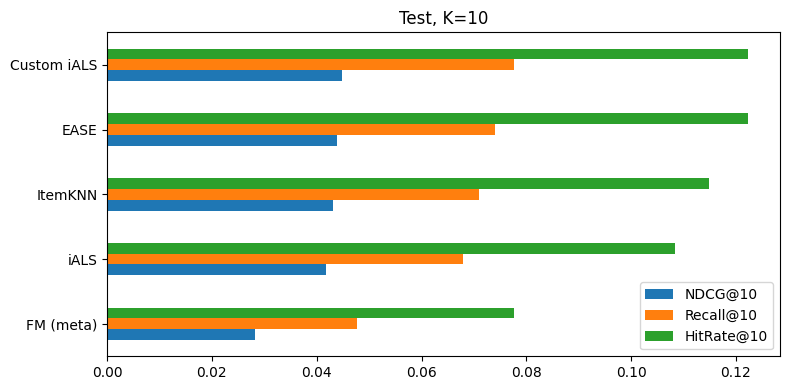

ItemKNN


,k,shrink,alpha,NDCG@10,Recall@10,HitRate@10,Coverage@10,sec
33,200,50,0.3,0.033995,0.056632,0.096419,0.695284,0.075635
24,100,50,0.3,0.033795,0.055598,0.094582,0.721251,0.069127
30,200,10,0.3,0.032782,0.054675,0.093664,0.755697,0.077030


iALS


,factors,lam,alpha,NDCG@10,Recall@10,HitRate@10,Coverage@10,sec
0,32,0.05,5,0.040182,0.064962,0.109275,0.268680,2.038397
6,32,5.00,5,0.040173,0.065689,0.110193,0.255962,2.046871
3,32,0.50,5,0.040100,0.065115,0.109734,0.267621,2.042653


EASE


,lam,NDCG@10,Recall@10,HitRate@10,Coverage@10,sec
4,3000,0.036228,0.060761,0.102388,0.618442,0.100732
1,200,0.036102,0.059502,0.101010,0.671966,0.103065
3,1000,0.036013,0.058891,0.098714,0.632220,0.102378


FM (meta)


,dim,lr,l2,epochs,NDCG@10,Recall@10,HitRate@10,Coverage@10,sec
3,16,0.010,0.00100,10,0.030491,0.046226,0.089073,0.254902,1.396070
1,16,0.003,0.00100,10,0.030308,0.051459,0.093664,0.054584,1.392402
2,16,0.010,0.00001,10,0.030190,0.045400,0.087695,0.260731,1.387778


Custom iALS


,factors,lam,alpha_pos,alpha_neg,tau_days,gamma,NDCG@10,Recall@10,HitRate@10,Coverage@10,sec
6,32.0,0.05,5.0,5,730,0.3,0.040970,0.067570,0.113407,0.187069,2.096002
10,32.0,0.05,5.0,20,730,0.3,0.040913,0.067402,0.113407,0.185480,2.102201
7,32.0,0.05,5.0,5,730,1.0,0.040823,0.066201,0.112029,0.186010,2.108060


In [38]:
ax = table[['NDCG@10', 'Recall@10', 'HitRate@10']].sort_values('NDCG@10').plot.barh(figsize=(8, 4))
ax.set_title('Test, K=10')
plt.tight_layout()
plt.show()
json.dump({'config': CFG, 'best': best, 'test': final}, open('results.json', 'w'), indent=2, default=str)
for n, r in results_val.items():
    print(n)
    display(r.head(3))

## 6. Выводы

В ходе работы были реализованы и сравнены пять рекомендательных моделей: ItemKNN, iALS, EASE, факторизационная машина (FM) с метапризнаками и Custom iALS с самостоятельно разработанным целевым сигналом. Работа была с датасетом Amazon Video Games  разбиением взаимодействий на train (80%), validation (10%) и test (10%). Гиперпараметры подбирались по NDCG@10 на validation, после чего модели обучались на train+validation и оценивались на test. Для всех моделей применялись одинаковые правила формирования рекомендаций и критерий релевантности: новым релевантным объектом считался товар с оценкой не ниже 4.

Сравнение качества моделей:
Лучший результат по основной метрике NDCG@10 показала Custom iALS. Она также достигла наибольшего Recall@10.
Оптимальные параметры Custom iALS - 32 латентных фактора, регуляризация 0.05, alpha_pos = 5, alpha_neg = 5, tau_days = 730 и gamma = 0.3.

EASE заняла второе место по NDCG@10, лишь немного уступив Custom iALS. При этом она обеспечила значительно больший охват каталога — Coverage@10. Для EASE лучшим значением регуляризации оказалось 3000. Таким образом, EASE представляет собой сильную альтернативу, особенно если важны не только точность рекомендаций, но и разнообразие рекомендуемых объектов на уровне всего каталога.

ItemKNN также показала конкурентоспособный результат NDCG@10 при 200 соседях, shrinkage = 50 и alpha = 0.3. Кроме того, эта модель достигла максимального Coverage@10. Это означает, что ItemKNN охватывала наибольшую долю каталога среди рассмотренных методов, хотя немного уступала лидерам по точности ранжирования.

Базовая iALS оказался ниже Custom iALS, EASE и ItemKNN,

Модель FM (meta) получила самую низкую NDCG@10

Ограничения эксперимента:
Несмотря на единый протокол оценки, исследование имеет несколько ограничений.

Во-первых, пользователи без достаточной истории и объекты, отсутствующие в обучающем каталоге, не рассматривались. Поэтому результаты нельзя напрямую переносить на задачу рекомендаций новым пользователям и товарам.

Во-вторых, пользовательская подвыборка и каталог формировались с использованием полного набора данных до временного разбиения. Это создаёт риск смещения отбора за счёт информации о будущей активности, хотя обучение моделей выполнялось на соответствующих обучающих взаимодействиях.

В-третьих, релевантность определялась по наблюдаемым оценкам не ниже 4. Отсутствие положительного отзыва не обязательно означает отсутствие интереса к товару, поэтому офлайн-метрики не полностью отражают реальное качество рекомендаций.